In [1]:
import numpy as np
import sys
import os
# Get the absolute path of the main directory
main_dir = os.path.abspath(os.path.join(os.getcwd(), ".."))
# Add the main directory to sys.path
sys.path.append(main_dir)
from pymooOptFunctions.pymooOptFunctions import *
import time

from pymoo.algorithms.soo.nonconvex.cmaes import CMAES
from pymoo.algorithms.moo.nsga2 import NSGA2
from pymoo.algorithms.soo.nonconvex.ga import GA
from pymoo.optimize import minimize
from pymoo.termination import get_termination

## **NLSE**

In [2]:
nvar=51
problem = pymooNLSE(n_var=nvar, eps=1e-4)
# initial_guess = np.ones(problem.n_var)-0.03*np.random.random(nvar)*np.abs(np.linspace(-1, 1, nvar))
# initial_guess = 1/np.cosh(np.linspace(-1, 1, nvar))+0.08*np.random.random(nvar)
initial_guess = 1-0.8*np.random.random(nvar)*np.abs(np.linspace(-1, 1, nvar))
initial_guess[nvar//2]=1
termination = get_termination('soo', ftol=1e-6, period=100, n_max_gen=16000, n_max_evals=np.inf, xtol=1e-10) and get_termination('time', '00:01:00')#get_termination('n_gen', 8000)
algorithm = CMAES(sigma=0.2620047168931698, pop_size=1000, restarts= 3, bipop=True,  incpopsize=2)#(sigma=0.1, pop_size=100, restarts=1, bipop=True, incpopsize=3)#x0=np.ones(nvar))

CMAESres = minimize(problem, algorithm, termination, verbose=True)#, seed=1,
               #verbose=True)


# algorithm = NSGA2(pop_size=100)

# NSGAres = minimize(problem,
#                algorithm,
#                termination,
#                ('n_gen', 5000),
#                seed=1,
#                verbose=True)

# algorithm = GA(
#     pop_size=3000,
#     eliminate_duplicates=True)


# GAres = minimize(problem,
#                algorithm,
#                termination,
#                seed=1,
#                verbose=True)


n_gen  |  n_eval  |     f_avg     |     f_min     | run  |   fpop   | n_pop |     sigma     | min_std  | max_std  |   axis  
     1 |       20 |  2.027995E+07 |  6.836221E+05 |    1 |  6.8E+05 |  1000 |  0.2620047169 |  0.26200 |  0.26202 |  1.00005
     2 |     1020 |  6.161127E+06 |  6.420899E+05 |    1 |  6.4E+05 |  1000 |  0.3017187081 |  0.29170 |  0.30824 |  1.19508
     3 |     2020 |  6.090680E+06 |  6.272310E+05 |    1 |  6.3E+05 |  1000 |  0.3501696356 |  0.33004 |  0.36621 |  1.32028
     4 |     3020 |  6.446883E+06 |  5.787202E+05 |    1 |  5.8E+05 |  1000 |  0.3983501417 |  0.36656 |  0.41560 |  1.44162
     5 |     4020 |  6.532805E+06 |  5.787202E+05 |    1 |  6.8E+05 |  1000 |  0.4356145758 |  0.39629 |  0.46121 |  1.58239
     6 |     5020 |  1.037653E+07 |  5.787202E+05 |    1 |  6.9E+05 |  1000 |  0.4723340043 |  0.42089 |  0.50389 |  1.69759
     7 |     6020 |  1.008692E+07 |  5.787202E+05 |    1 |  6.3E+05 |  1000 |  0.5015874403 |  0.44017 |  0.53854 |  1.83325


In [3]:
print(f'The CMA-ES MAE respect to the analytical solution is MAE: {np.sum((1/np.cosh(np.linspace(-1, 1, nvar)) - CMAESres.X)**2) / nvar}')
# print(f'The GA MAE: {np.sum((1/np.cosh(np.linspace(-1, 1, nvar)) - GAres.X)**2) / nvar}')
# print(f'The NSGA MAE: {np.sum((1/np.cosh(np.linspace(-1, 1, nvar)) - NSGAres.X)**2) / nvar}')
#con 425 variables npop=100  fmin 5.64e6 después de 13000 generaciones
#con 425 variables npop=1000  fmin  después de 13000 generaciones

The CMA-ES MAE respect to the analytical solution is MAE: 0.06876688402056468


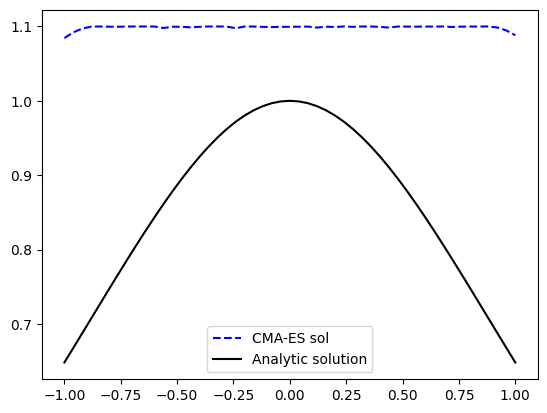

In [4]:
import matplotlib.pyplot as plt
plt.plot(np.linspace(-1, 1, nvar), CMAESres.X, 'b--', label='CMA-ES sol')
plt.plot(np.linspace(-1, 1, nvar), 1/np.cosh(np.linspace(-1, 1, nvar)),  'k-', label='Analytic solution')
plt.legend();

In [5]:
# ##Prueba de generación de población inicial con
# ## P R O C E S O   G A U S S I A N O #######
# ############################################

# import numpy as np
# n_variables = 50
# X_grid = np.linspace(start=0, stop=5, num=n_variables).reshape(-1,1) #para que sean n_variables filas y 1 columna
# X_train = X_grid[[0, -1], 0].reshape(-1, 1)#Para NLSE np.array((0, )).reshape(-1,1)
# Y_train = np.array((0, 0)).reshape(-1,1) #Para NLSE np.linspace(start=1, stop=1, num=1).reshape(-1,1) #Para que sea 2D array
# init_data=(X_train, Y_train)
# size_gen=50

# from sklearn.gaussian_process import GaussianProcessRegressor
# from sklearn.gaussian_process.kernels import RBF

# def initialize_population(size_gen, grid, init_kernels, init_constraints):
#     '''
#     SMART initialization for suitable solutions creation.
#     Creates the initial population from the desired number of distinct RBF kernels. A 'grid search' is performed over the length scale parameter.
#     The minimum value for the length scale is defined depending on the grid size, as lambda = grid_size/sqrt(2). 
#     The maximum value is defined as half the total range of the independent variable.
#     init_constraints: tuple of tuples with initial known observations or constraints 
#                ((grid points x ), (observations f(x))) = ((x_1, x_2, ..., x_m), (f(x_1), f(x_2), ..., f(x_m)))
#                both arrays must be shape ((m, 1)) where m=grid points where observations are known. Observations must coincide with some of the points defined in the grid
#     '''

#     grid_size = grid[-1,0] - grid[-2, 0]
#     problem_size = grid[-1,0] - grid[0,0]
            
#     lengths = np.linspace(grid_size/np.sqrt(2), problem_size/2, init_kernels)
#     samplesperkernel = int(size_gen/init_kernels)
#     for scale in lengths:
#         kernel = 0.5 * RBF(length_scale=scale,  length_scale_bounds='fixed') #length_scale_bounds=(scale[0], scale[0]))
#         gaussian_process = GaussianProcessRegressor(kernel=kernel, n_restarts_optimizer=9)
#         gaussian_process.fit(init_constraints[0], init_constraints[1])

#         if scale==lengths[0]:
#             init_generation=gaussian_process.sample_y(grid, n_samples=samplesperkernel).T
#         else:
#             init_generation = np.concatenate([init_generation, gaussian_process.sample_y(grid, n_samples=samplesperkernel).T])
#     return init_generation

# initial_guess = initialize_population(size_gen=size_gen, grid=X_grid, init_kernels=10, init_constraints=init_data)
# import matplotlib.pyplot as plt
# for i in range(len(initial_guess)):
#     plt.plot(np.linspace(0, 5, n_variables), initial_guess[i,:], alpha=0.3)

# from OptFunctions.oneDwellfunctions import *
# evals = []
# for i in range(len(initial_guess)):
#     evals.append(oneD_wellExpEexcitated(initial_guess[i, :], L=5, E=params['E0'], Psi=params['Psi0'], exponential=False))

# print(np.argsort(evals)[0])
# import matplotlib.pyplot as plt
# plt.plot(np.linspace(0, 5, n_variables[0]), initial_guess[np.argsort(evals)[0],:], alpha=0.3)

## **Infinite Well**

In [23]:
def _normalizeCMAES(data:np.array, grid_size: float):
    '''
    Normalizes the solutions i.e. multiply by a constant so that the integral of the solution^2 = 1.
    Be aware that integration depends on problem definition and size!!!!
    '''
    #grid_size = L/variables     dx of integral
    #grid_size = 5/(self.n_variables-1)

    #Assuming a constant size grid we know grid size independently of problem parameters (better code-wise)
    #self.grid_size = grid_X[-1,0] - grid_X[-2, 0]
    integral = 0
    for var in range(data.shape[0]):
        integral = integral + (data[var]**2)*grid_size ##Tener en cuenta posibles cambios en tamaño grid!!! L caja = 5 

    A = (1/integral)**0.5
    data = A * data
    return data

In [ ]:
import numpy as np
import sys
import os
# Get the absolute path of the main directory
main_dir = os.path.abspath(os.path.join(os.getcwd(), ".."))
# Add the main directory to sys.path
sys.path.append(main_dir)
from pymooOptFunctions.pymooOptFunctions import *
import time
 
from pymoo.algorithms.soo.nonconvex.cmaes import CMAES
from pymoo.algorithms.moo.nsga2 import NSGA2
from pymoo.algorithms.soo.nonconvex.ga import GA
from pymoo.optimize import minimize
from pymoo.termination import get_termination
######################################################################################
######################################################################################
############## POZO DE POTENCIAL INFINITO 1D WELL ####################################
######################################################################################
n_variables = [20, 50, 425, 800]
Resultados = np.empty((1, 9, 5)) 
# 5 métricas [MSE, E, E%, GP_1000, t_exc]
experimento = int(0)
print('\nInfinite Well IN PROGRESS\n')
L=5
#Energías teóricas
Eg = (2*np.pi)**2/(8*L**2*1)
En=[]
for i in range(4):
    e=(i+1)**2*Eg
    En.append(e)

grid = np.linspace(0, L, n_variables[1])
grid_size = grid[-1]-grid[-2]
APsisWell = {}
for n in range(4):
    APsisWell[f'APsi{n}'] = (2/L)**0.5*np.sin((n+1)*np.pi*grid/L)

#Ground state n=1
print(f'F should be approx {En[0]**2}') #-0.9618')

problem = pymoooWellGround(n_var=n_variables[1], eps=1e-4)
# initial_guess = np.sin(np.linspace(0, L, n_variables[1
# ])*2*np.pi/5)
# initial_guess[0] = 0
# initial_guess[-1] = 0
#initial_guess = np.vstack((initial_guess, np.random.random(n_variables[1])))
termination = get_termination('n_gen', 5000)
algorithm = CMAES(sigma=0.01, pop_size=50, restarts=1, bipop=True, incpopsize=3)#x0=initial_guess)
resground = minimize(problem, algorithm, termination)#,seed=1,verbose=True)
Resultados[experimento, 4, 4] = resground.exec_time

Psi_fund=resground.X
Psi_fund = _normalizeCMAES(Psi_fund, grid_size)
E_fund = np.sqrt(resground.F[0]) # def función de coste la energía se determina a partir del fitness raiz cuadrada diff Ener
Resultados[experimento, 4, 1] = E_fund
Resultados[experimento, 4, 2] = abs(E_fund-En[0])/En[0]*100 
params = {'L':L, 'E': E_fund, 'Psi': Psi_fund}
print(f'\n  |Psi0> done {resground.F}\n')

#1excitated state n=2
print(f'F should be approx {(En[1]-En[0])**2}') #-0.7042')
problem = pymooWell1(n_var=n_variables[1], eps=1e-4, E=E_fund, Psi=Psi_fund)
termination = get_termination('n_gen', 5000)
algorithm = CMAES(sigma=0.01, pop_size=50, restarts=1, bipop=True, incpopsize=3)#, x0=initial_guess[46, :])
resWell1 = minimize(problem, algorithm, termination)#,seed=1,verbose=True)
Resultados[experimento, 5, 4] = resWell1.exec_time

Psi_1=resWell1.X
Psi_1 = _normalizeCMAES(Psi_1, grid_size)
E1 = np.sqrt((resWell1.F[0]))
Resultados[experimento, 5, 1] = E_fund + E1
Resultados[experimento, 5, 2] = abs(E_fund + E1 -En[1])/En[1]*100
params = {'L':L, 'E0': E_fund, 'Psi0': Psi_fund, 'E1':E1, 'Psi1': Psi_1}
print(f'\n  |Psi1> done {resWell1.F}\n')

#2nd excitated state n=3
print(f'F should be approx {(En[2]-En[1])**2}') #-0.3775')
problem = pymooWell2(n_var=n_variables[1], eps=1e-4, E0=E_fund, Psi0=Psi_fund, E1=E1, Psi1=Psi_1)
termination = get_termination('n_gen', 5000)
algorithm = CMAES(sigma=0.01, pop_size=50, restarts=1, bipop=True, incpopsize=3)#x0=initial_guess)
resWell2 = minimize(problem, algorithm, termination)#,seed=1,verbose=True)
Resultados[experimento, 6, 4] = resWell2.exec_time
Psi_2=resWell2.X
Psi_2 = _normalizeCMAES(Psi_2, grid_size)
E2 = np.sqrt(resWell2.F[0])
Resultados[experimento, 6, 1] = E_fund + E1 + E2
Resultados[experimento, 6, 2] = abs(E_fund + E1 +E2 -En[2])/En[2]*100

params = {'L':L, 'E0': E_fund, 'Psi0': Psi_fund, 'E1':E1, 'Psi1': Psi_1, 'E2': E2, 'Psi2': Psi_2}
print(f'\n  |Psi2> done {resWell2.F}\n')

#3rd excitated state n=4
print(f'F should be approx {(En[3]-En[2])**2}') #-0.1482')
problem = pymooWell3(n_var=n_variables[1], eps=1e-4, E0=E_fund, Psi0=Psi_fund, E1=E1, Psi1=Psi_1, E2=E2, Psi2=Psi_2)
termination = get_termination('n_gen', 5000)
algorithm = CMAES(sigma=0.01, pop_size=50, restarts=1, bipop=True, incpopsize=3)#x0=initial_guess)
resWell3 = minimize(problem, algorithm, termination)#,seed=1,verbose=True)
Resultados[experimento, 7, 4] = resWell3.exec_time
Psi_3 = resWell3.X
Psi_3 = _normalizeCMAES(Psi_3, grid_size)
E3 = np.sqrt(resWell3.F[0])
Resultados[experimento, 7, 1] = E_fund + E1 + E2 + E3
Resultados[experimento, 7, 2] = abs(E_fund + E1 +E2+E3 -En[3])/En[3]*100
params = {'L':L, 'E0': E_fund, 'Psi0': Psi_fund, 'E1':E1, 'Psi1': Psi_1, 'E2': E2, 'Psi2': Psi_2, 'E3':E3, 'Psi3': Psi_3}
print(f'\n  |Psi3> done {resWell3.F}\n')
#Cálculos de métricas error MSE de cada estado con estado teórico
MSEs = []
for i in range(4):
    mse = min(np.mean((params[f'Psi{i}'] - APsisWell[f'APsi{i}'])**2), np.mean((-1*params[f'Psi{i}'] - APsisWell[f'APsi{i}'])**2))
    Resultados[experimento, i+4, 0] = mse
    MSEs.append(mse)

#MSE_Well = np.sum(MSEs)
#Mean is more correct because sum will make the MSE in NLSE problem probably always smaller 
#MSE_Well = np.mean(MSEs)

print('\nInfinite Well DONE\n')



Infinite Well IN PROGRESS

F should be approx 0.03896363641360097

  |Psi0> done [0.0389213]

F should be approx 0.35067272772240865

  |Psi1> done [0.28924587]

F should be approx 0.9740909103400243

  |Psi2> done [0.41566675]

F should be approx 1.909218184266447

  |Psi3> done [0.58284483]


Infinite Well DONE



In [6]:
MSEs

[7.942636285067044e-10,
 0.002299543068943997,
 0.00525306174580391,
 0.009214097331777192]

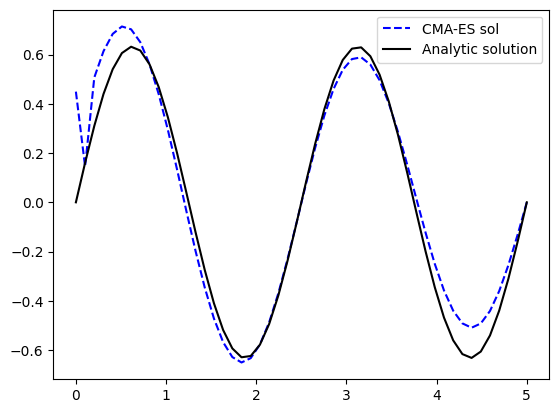

In [13]:
import matplotlib.pyplot as plt
f=3
plt.plot(np.linspace(0, 5, n_variables[1]), params[f'Psi{f}'], 'b--', label='CMA-ES sol')
#plt.plot(np.linspace(0, 5, n_variables[1]), initial_guess, 'r--', label='initial guess')
plt.plot(np.linspace(0, 5, n_variables[1]), APsisWell[f'APsi{f}'],  'k-', ms=3, label='Analytic solution')
plt.legend()

## **Quantum Harmonic Oscillator**

In [1]:
import numpy as np
def _normalizeCMAES(data:np.array, grid_size: float):
    '''
    Normalizes the solutions i.e. multiply by a constant so that the integral of the solution^2 = 1.
    Be aware that integration depends on problem definition and size!!!!
    '''
    #grid_size = L/variables     dx of integral
    #grid_size = 5/(self.n_variables-1)

    #Assuming a constant size grid we know grid size independently of problem parameters (better code-wise)
    #self.grid_size = grid_X[-1,0] - grid_X[-2, 0]
    integral = 0
    for var in range(data.shape[0]):
        integral = integral + (data[var]**2)*grid_size ##Tener en cuenta posibles cambios en tamaño grid!!! L caja = 5 

    A = (1/integral)**0.5
    data = A * data
    return data

In [ ]:
import numpy as np
import sys
import os
# Get the absolute path of the main directory
main_dir = os.path.abspath(os.path.join(os.getcwd(), ".."))
# Add the main directory to sys.path
sys.path.append(main_dir)
from pymooOptFunctions.pymooOptFunctions import *
import time
 
from pymoo.algorithms.soo.nonconvex.cmaes import CMAES
from pymoo.algorithms.moo.nsga2 import NSGA2
from pymoo.algorithms.soo.nonconvex.ga import GA
from pymoo.optimize import minimize
from pymoo.termination import get_termination
######################################################################################
######################################################################################
############## Quantum Harmonic Oscillator 1D ####################################
######################################################################################
n_variables = [20, 50, 425, 800]
Resultados = np.empty((1, 9, 5)) 
#Medidas de los experimentos se guardan en un array.shape [Nexp, 9, 5]
#porque se harán Nexp ejecuciones de los problemas
# 9 filas porque tenemos 4 estados de Oscilador, 4 de pozo y 1 de NLSE
# 5 métricas [MSE, E, E%, GP_1000, t_exc]
# en este orden de manera que por ejemplo los E% de los Nexp del estado Psi0 del pozo es el elemento [:, 4, 2] del array de Resultados
experimento = int(0)
print('\nInfinite Well IN PROGRESS\n')
#Energías teóricas
Eg = 0.5
En=[]
for i in range(4):
    e= Eg + 1*i
    En.append(e)

X_grid = np.linspace(start=-4, stop=4, num=n_variables[1]).reshape(-1,1)
grid_size = ((X_grid[-1]-X_grid[0])/(len(X_grid)-1))

########################################################
#### Analytical solutions definitions ##################
########################################################
#Ground state
APsi0 = np.exp(-X_grid**2/2)
integral =0
for i in range(len(APsi0)):
    integral = integral + (APsi0[i]**2)*((X_grid[-1]-X_grid[0])/(len(APsi0)-1))

B = (1/integral)**0.5
APsi0 = B * APsi0

#1st excitated state
APsi1 = np.exp(-X_grid**2/2)*2*X_grid
integral =0
for i in range(len(APsi1)):
    integral = integral + (APsi1[i]**2)*((X_grid[-1]-X_grid[0])/(len(APsi1)-1))

B = (1/integral)**0.5
APsi1 = -1 * B * APsi1 #signo menos para correspondencia con solución algoritmo (simetrización)

#if results_dict['eda_resultExpE1'].sel_inds_hist[-1, 0, :-1][10]>0:
   # APsi1 = -APsi1


#2nd excitated state
APsi2 = np.exp(-X_grid**2/2)*(4*X_grid**2-2)
integral =0
for i in range(len(APsi2)):
    integral = integral + (APsi2[i]**2)*((X_grid[-1]-X_grid[0])/(len(APsi2)-1))

B = (1/integral)**0.5
APsi2 = B * APsi2

#if results_dict['eda_resultExpE2'].sel_inds_hist[-1, 0, :-1][3]<0:
   # APsi2=-APsi2

#3rd excitated state
APsi3 = np.exp(-X_grid**2/2)*(8*X_grid**3-12*X_grid)
integral =0
for i in range(len(APsi3)):
    integral = integral + (APsi3[i]**2)*((X_grid[-1]-X_grid[0])/(len(APsi3)-1))

B = (1/integral)**0.5
APsi3 = -1 * B * APsi3 #signo menos para correspondencia con solución algoritmo (simetrización)

APsis = {}
APsis['APsi0'] = APsi0[:, 0]
APsis['APsi1'] = APsi1[:, 0]
APsis['APsi2'] = APsi2[:, 0]
APsis['APsi3'] = APsi3[:, 0]
X_grid = X_grid[:, 0]

############################################################################
############################################################################

#Ground state n=1
print(f'F should be approx {En[0]**2}')

problem = pymoooOscGround(n_var=n_variables[1], grid=X_grid, eps=1e-4)
termination = get_termination('n_gen', 5500)
algorithm = CMAES(sigma=0.01, pop_size=50, restarts=1, bipop=True, incpopsize=3)#x0=initial_guess)
resground = minimize(problem, algorithm, termination)#,seed=1,verbose=True)
Resultados[experimento, 0, 4] = resground.exec_time

Psi_fund=resground.X
Psi_fund = _normalizeCMAES(Psi_fund, grid_size)
E_fund = np.sqrt(resground.F[0]) # def función de coste la energía se determina a partir del fitness raiz cuadrada diff Ener
Resultados[experimento, 0, 1] = E_fund
Resultados[experimento, 0, 2] = abs(E_fund-En[0])/En[0]*100 
params = {'E': E_fund, 'Psi': Psi_fund}
print(f'\n  |Psi0> done {resground.F}\n')

#1excitated state n=2
print(f'F should be approx {(En[1]-En[0])**2}') #-0.7042')
problem = pymoooOsc1(n_var=n_variables[1], grid=X_grid, E0=E_fund, Psi0=Psi_fund, eps=1e-4)
termination = get_termination('n_gen', 5500)
algorithm = CMAES(sigma=0.01, pop_size=50, restarts=1, bipop=True, incpopsize=3)#, x0=initial_guess[46, :])
resOsc1 = minimize(problem, algorithm, termination)#,seed=1,verbose=True)
Resultados[experimento, 1, 4] = resOsc1.exec_time

Psi_1=resOsc1.X
Psi_1 = _normalizeCMAES(Psi_1, grid_size)
E1 = np.sqrt((resOsc1.F[0]))
Resultados[experimento, 1, 1] = E_fund + E1
Resultados[experimento, 1, 2] = abs(E_fund + E1 -En[1])/En[1]*100
params = {'E0': E_fund, 'Psi0': Psi_fund, 'E1':E1, 'Psi1': Psi_1}
print(f'\n  |Psi1> done {resOsc1.F}\n')

#2nd excitated state n=3
print(f'F should be approx {(En[2]-En[1])**2}') #-0.3775')
problem = pymoooOsc2(n_var=n_variables[1],  grid=X_grid, eps=1e-4, E0=E_fund, Psi0=Psi_fund, E1=E1, Psi1=Psi_1)
termination = get_termination('n_gen', 5500)
algorithm = CMAES(sigma=0.01, pop_size=50, restarts=1, bipop=True, incpopsize=3)#x0=initial_guess)
resOsc2 = minimize(problem, algorithm, termination)#,seed=1,verbose=True)
Resultados[experimento, 2, 4] = resOsc2.exec_time
Psi_2=resOsc2.X
Psi_2 = _normalizeCMAES(Psi_2, grid_size)
E2 = np.sqrt(resOsc2.F[0])
Resultados[experimento, 2, 1] = E_fund + E1 + E2
Resultados[experimento, 2, 2] = abs(E_fund + E1 +E2 -En[2])/En[2]*100

params = {'E0': E_fund, 'Psi0': Psi_fund, 'E1':E1, 'Psi1': Psi_1, 'E2': E2, 'Psi2': Psi_2}
print(f'\n  |Psi2> done {resOsc2.F}\n')

#3rd excitated state n=4
print(f'F should be approx {(En[3]-En[2])**2}') #-0.1482')
problem = pymoooOsc3(n_var=n_variables[1],  grid=X_grid, eps=1e-4, E0=E_fund, Psi0=Psi_fund, E1=E1, Psi1=Psi_1, E2=E2, Psi2=Psi_2)
termination = get_termination('n_gen', 5500)
algorithm = CMAES(sigma=0.01, pop_size=50, restarts=1, bipop=True, incpopsize=3)#x0=initial_guess)
resOsc3 = minimize(problem, algorithm, termination)#,seed=1,verbose=True)
Resultados[experimento, 3, 4] = resOsc3.exec_time
Psi_3 = resOsc3.X
Psi_3 = _normalizeCMAES(Psi_3, grid_size)
E3 = np.sqrt(resOsc3.F[0])
Resultados[experimento, 3, 1] = E_fund + E1 + E2 + E3
Resultados[experimento, 3, 2] = abs(E_fund + E1 +E2+E3 -En[3])/En[3]*100
params = {'E0': E_fund, 'Psi0': Psi_fund, 'E1':E1, 'Psi1': Psi_1, 'E2': E2, 'Psi2': Psi_2, 'E3':E3, 'Psi3': Psi_3}
print(f'\n  |Psi3> done {resOsc3.F}\n')
#Cálculos de métricas error MSE de cada estado con estado teórico
MSEs = []
for i in range(4):
    mse = min(np.mean((params[f'Psi{i}'] - APsis[f'APsi{i}'])**2), np.mean((-1*params[f'Psi{i}'] - APsis[f'APsi{i}'])**2))
    Resultados[experimento, i, 0] = mse
    MSEs.append(mse)

#MSE_Well = np.sum(MSEs)
#Mean is more correct because sum will make the MSE in NLSE problem probably always smaller 
#MSE_Well = np.mean(MSEs)

print('\nQuantum Harmonic Oscillator DONE\n')



Infinite Well IN PROGRESS

F should be approx 0.25

  |Psi0> done [0.24916653]

F should be approx 1.0

  |Psi1> done [0.77684919]

F should be approx 1.0

  |Psi2> done [0.80686087]

F should be approx 1.0

  |Psi3> done [0.8109221]


Quantum Harmonic Oscillator DONE



In [6]:
MSEs

[1.8793807250225729e-07,
 0.005911758373408933,
 0.007152109874333334,
 0.008411669549962817]

<>:9: SyntaxWarning: invalid escape sequence '\P'
<>:9: SyntaxWarning: invalid escape sequence '\P'
/tmp/ipykernel_50490/2288025947.py:9: SyntaxWarning: invalid escape sequence '\P'
  plt.plot(X_grid, e+params[f'Psi{i}'], 'b-', label=f'$\Psi(x)$', alpha=0.9)


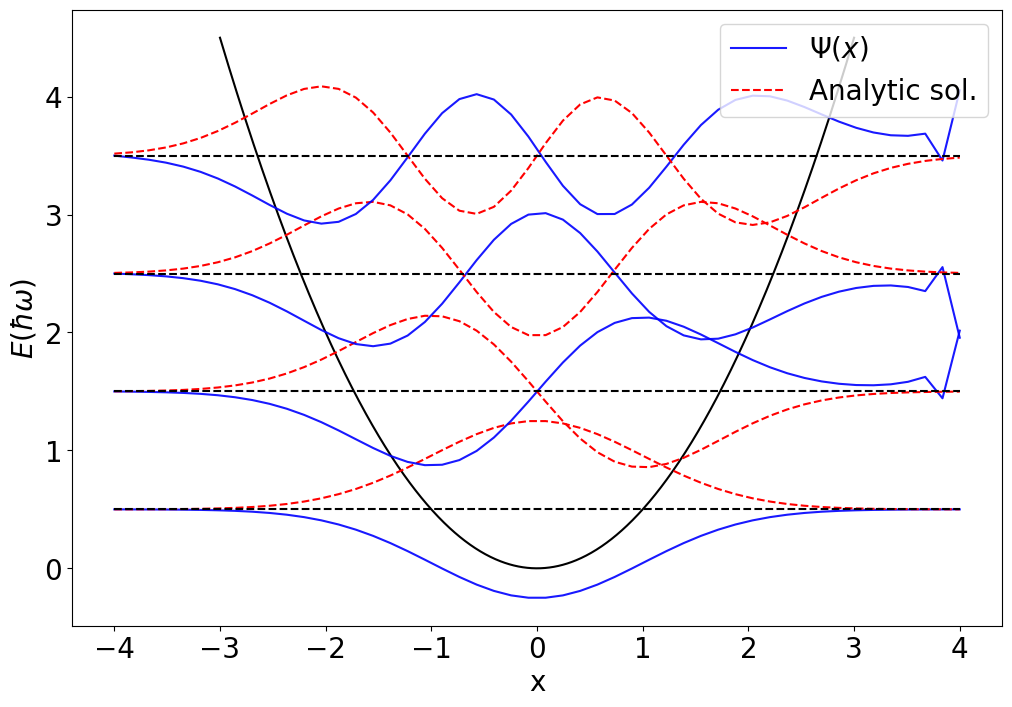

In [7]:
import matplotlib.pyplot as plt
plt.figure(figsize=(12, 8))
plt.rcParams.update({'font.size':20})
plt.plot(np.linspace(-3,3, 1000), 0.5*np.linspace(-3,3,1000)**2, 'k-')

e = 0.5
for i in range(4):
    if i == 3:
        plt.plot(X_grid, e+params[f'Psi{i}'], 'b-', label=f'$\Psi(x)$', alpha=0.9)
        plt.plot(np.linspace(-4,4,n_variables[1]), e+APsis[f'APsi{i}'], 'r--', label='Analytic sol.')
        plt.plot(np.linspace(-4,4,2), np.linspace(e,e,2), 'k--')
        e+=1
    else:
        plt.plot(X_grid, e+params[f'Psi{i}'], 'b-', alpha=0.9)
        plt.plot(np.linspace(-4,4,n_variables[1]), e+APsis[f'APsi{i}'], 'r--')
        plt.plot(np.linspace(-4,4,2), np.linspace(e,e,2), 'k--')
        e+=1


#plt.gca().set_title('Función de onda $\Psi(x)$')
plt.xlabel('x')
plt.gca().set_ylabel(r'$E (\hbar \omega)$')
plt.legend(loc = 'upper right');
#plt.savefig('Figures/QHObyEGPAbigfont.pdf');